# random forest vs xgboost

predicting house price with a random forest and with xgboost, then putting both together as a voting and a stacking model. cleaned data comes from `houses_eda.ipynb`.

In [1]:
import json, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.tree import DecisionTreeRegressor
from interpret.glassbox import ExplainableBoostingRegressor
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42

## 1. load data and hold out one listing

one random listing is taken out before any split. it is not used for training, tuning or testing, and i use it at the end to try the saved model on a house it has never seen.

In [2]:
df = pd.read_csv('../data/processed/houses_clean.csv')
df['is_member'] = df['is_member'].map({True: 1.0, False: 0.0, 'True': 1.0, 'False': 0.0})
print(df.shape)

holdout = df.sample(1, random_state=SEED)
df = df.drop(holdout.index).reset_index(drop=True)
print('rows left for training and testing:', len(df))
holdout.T

(27723, 11)
rows left for training and testing: 27722


,19733
price,35000000.0
bedrooms,6.0
bathrooms,4.0
house_size_sqft,3500.0
land_size_perches,20.0
location,Piliyandala
district,Colombo
membership_level,free
is_verified,0
is_member,0.0


In [3]:
features = ['bedrooms', 'bathrooms', 'house_size_sqft', 'land_size_perches', 'posted_month',
            'is_verified', 'location', 'district', 'membership_level', 'is_member']

# save the held out listing for inference (features and the real price)
sample = holdout[features].iloc[0].to_dict()
sample = {k: (None if pd.isna(v) else (v.item() if hasattr(v, 'item') else v)) for k, v in sample.items()}
with open('../model/houses_holdout_sample.json', 'w') as f:
    json.dump({'features': sample, 'actual_price': float(holdout['price'].iloc[0])}, f, indent=2)

X = df[features]
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(X_train.shape, X_test.shape)

(22177, 10) (5545, 10)


## 2. preprocessing

all of this sits in one `ColumnTransformer`, so it is fitted on the training rows only.

- numbers: fill missing with the median, `log1p` on house size and land size (both skewed), then standard scaling
- categories (location, district, membership): fill with the most common value and one hot encode. locations with fewer than 30 ads go into one rare group, and a location the model has never seen at prediction time falls into that group too
- target: price is skewed, so the model learns `log(price)` and the result is turned back into rupees

scaling does nothing for trees, but it is cheap and keeps the pipeline general.

In [4]:
log_cols = ['house_size_sqft', 'land_size_perches']
other_num = ['bedrooms', 'bathrooms', 'posted_month', 'is_verified', 'is_member']
cat_cols = ['location', 'district', 'membership_level']

preprocess = ColumnTransformer([
    ('log_num', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
        ('scale', StandardScaler()),
    ]), log_cols),
    ('num', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
    ]), other_num),
    ('cat', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(min_frequency=30, handle_unknown='infrequent_if_exist', sparse_output=False)),
    ]), cat_cols),
])

def make_pipeline(regressor):
    model = TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)
    return Pipeline([('prep', preprocess), ('model', model)])

width = preprocess.fit(X_train).get_feature_names_out().shape[0]
print('features after preprocessing:', width)

features after preprocessing: 116


## 3. choosing the parameters

defaults are built for general data, mine has about 22k rows, 117 columns after encoding and noisy asking prices, so i set these myself.

**random forest**
- `n_estimators` 150, fixed. more trees only lower the variance a bit and the saved model has to stay small enough for github
- `max_depth` 14 to unlimited. unlimited trees memorise noise, so i also try capped ones
- `min_samples_leaf` 3, 5 or 8. ads are noisy, a leaf of 1 just copies one ad. this also keeps the pickle small
- `max_features` 0.33 to 1.0. with so many one hot columns, looking at every column each split makes the trees too alike
- `max_samples` 0.6 to 1.0, row sampling per tree for more variety

**xgboost**
- `learning_rate` 0.05 to 0.1. small steps with more trees overfit less
- `max_depth` 4 to 8. boosting wants shallow trees, a forest wants deep ones
- `min_child_weight`, `gamma`, `reg_lambda` all limit how much a leaf can fit a few noisy ads
- `subsample` and `colsample_bytree` below 1 add randomness, like a forest
- `n_estimators` from early stopping, next cell

best number of rounds: 673


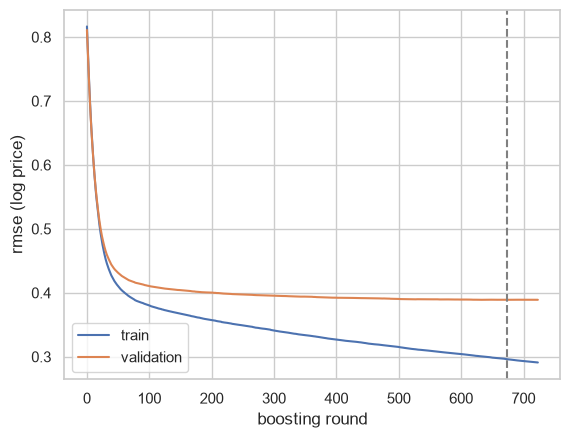

In [5]:
# how many boosting rounds are needed at lr 0.05 and depth 6?
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=SEED)
prep_tmp = clone(preprocess).fit(X_tr)

probe = XGBRegressor(n_estimators=2000, learning_rate=0.05, max_depth=6, subsample=0.8,
                     colsample_bytree=0.7, early_stopping_rounds=50, tree_method='hist', random_state=SEED, n_jobs=-1)
probe.fit(prep_tmp.transform(X_tr), np.log1p(y_tr),
          eval_set=[(prep_tmp.transform(X_tr), np.log1p(y_tr)), (prep_tmp.transform(X_val), np.log1p(y_val))],
          verbose=False)
history = probe.evals_result()
print('best number of rounds:', probe.best_iteration)

plt.plot(history['validation_0']['rmse'], label='train')
plt.plot(history['validation_1']['rmse'], label='validation')
plt.axvline(probe.best_iteration, color='grey', linestyle='--')
plt.xlabel('boosting round')
plt.ylabel('rmse (log price)')
plt.legend()
plt.show()

## 4. tuning

randomized search with 3 fold cross validation on the training set. the score is rmsle (rmse on log price), so a 10% miss counts the same for a 5 million house and a 100 million one.

In [6]:
kf = KFold(n_splits=3, shuffle=True, random_state=SEED)
score = 'neg_root_mean_squared_log_error'

rf_space = {
    'model__regressor__max_depth': [14, 18, 24, None],
    'model__regressor__min_samples_leaf': [3, 5, 8],
    'model__regressor__max_features': [0.33, 0.5, 0.7, 1.0],
    'model__regressor__max_samples': [0.6, 0.8, 1.0],
}
rf_pipe = make_pipeline(RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1))
rf_search = RandomizedSearchCV(rf_pipe, rf_space, n_iter=15, cv=kf, scoring=score, random_state=SEED, n_jobs=1, verbose=0)
rf_search.fit(X_train, y_train)
print('rf best cv rmsle:', round(-rf_search.best_score_, 4))
print(rf_search.best_params_)

rf best cv rmsle: 0.4006
{'model__regressor__min_samples_leaf': 3, 'model__regressor__max_samples': 1.0, 'model__regressor__max_features': 0.33, 'model__regressor__max_depth': 24}


In [7]:
BEST_ROUNDS = probe.best_iteration

xgb_space = {
    'model__regressor__n_estimators': [int(BEST_ROUNDS * f) for f in (0.6, 0.8, 1.0)],
    'model__regressor__learning_rate': [0.05, 0.08, 0.1],
    'model__regressor__max_depth': [4, 6, 8],
    'model__regressor__min_child_weight': [1, 3, 5],
    'model__regressor__subsample': [0.7, 0.85, 1.0],
    'model__regressor__colsample_bytree': [0.5, 0.7, 0.9],
    'model__regressor__reg_lambda': [1, 5, 10],
    'model__regressor__gamma': [0, 0.1, 0.3],
}
xgb_pipe = make_pipeline(XGBRegressor(tree_method='hist', random_state=SEED, n_jobs=-1))
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_space, n_iter=20, cv=kf, scoring=score, random_state=SEED, n_jobs=1, verbose=0)
xgb_search.fit(X_train, y_train)
print('xgb best cv rmsle:', round(-xgb_search.best_score_, 4))
print(xgb_search.best_params_)

xgb best cv rmsle: 0.3885
{'model__regressor__subsample': 0.7, 'model__regressor__reg_lambda': 10, 'model__regressor__n_estimators': 538, 'model__regressor__min_child_weight': 3, 'model__regressor__max_depth': 8, 'model__regressor__learning_rate': 0.05, 'model__regressor__gamma': 0, 'model__regressor__colsample_bytree': 0.7}


In [8]:
rf_best = rf_search.best_estimator_
xgb_best = xgb_search.best_estimator_

# default parameter versions, only as a reference to show what the tuning bought
rf_default = make_pipeline(RandomForestRegressor(random_state=SEED, n_jobs=-1)).fit(X_train, y_train)
xgb_default = make_pipeline(XGBRegressor(random_state=SEED, n_jobs=-1)).fit(X_train, y_train)

## 5. voting and stacking

voting averages the predictions of the tuned random forest and the tuned xgboost (the regression version of soft voting). stacking trains a ridge regression on their out of fold predictions to decide how much to trust each.

In [9]:
rf_model = clone(rf_best.named_steps['model'].regressor)
xgb_model = clone(xgb_best.named_steps['model'].regressor)

voting = make_pipeline(VotingRegressor([('rf', clone(rf_model)), ('xgb', clone(xgb_model))]))
stacking = make_pipeline(StackingRegressor(
    estimators=[('rf', clone(rf_model)), ('xgb', clone(xgb_model))],
    final_estimator=RidgeCV(), cv=3))

voting.fit(X_train, y_train)
stacking.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['bedrooms','bathrooms','house_size_sqft',...,'district', 'membership_level','is_member']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log_num', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. Thi

## 6. explainable boosting machine

the random forest and xgboost were both taught in the module, so this is the model i add from outside it. an ebm (explainable boosting machine) is a generalized additive model fitted by boosting. it learns one curve for each feature and a few curves for pairs of features, and the price is the sum of those curves. a forest or xgboost mixes all the features inside deep trees, so a single prediction cannot be read off. with an ebm every prediction is a plain sum, so the explanation is exact and not an approximation like shap.

it takes the raw columns and bins the numbers and handles categories and missing values itself, so there is no preprocessing step. the price is logged the same way as for the other models. i tune with the same 3 fold randomized search, but only 6 draws since an ebm fit is slower. the default and the tuned one are both scored below.

In [10]:
# the ebm takes the raw columns, it bins the numbers and handles categories and missing values itself
def make_ebm(**params):
    model = TransformedTargetRegressor(regressor=ExplainableBoostingRegressor(random_state=SEED, n_jobs=-1, **params),
                                       func=np.log1p, inverse_func=np.expm1)
    return Pipeline([('model', model)])

ebm_default = make_ebm().fit(X_train, y_train)

ebm_space = {
    'model__regressor__learning_rate': [0.01, 0.02, 0.05],
    'model__regressor__max_bins': [128, 256, 512],
    'model__regressor__interactions': [0, 5, 10, 20],
    'model__regressor__outer_bags': [4, 8],
    'model__regressor__smoothing_rounds': [0, 50, 200],
}
ebm_search = RandomizedSearchCV(make_ebm(), ebm_space, n_iter=6, cv=kf, scoring=score, random_state=SEED, n_jobs=1, verbose=0)
ebm_search.fit(X_train, y_train)
ebm_best = ebm_search.best_estimator_
print('ebm best cv rmsle:', round(-ebm_search.best_score_, 4))
print(ebm_search.best_params_)

ebm best cv rmsle: 0.4012
{'model__regressor__smoothing_rounds': 0, 'model__regressor__outer_bags': 8, 'model__regressor__max_bins': 128, 'model__regressor__learning_rate': 0.05, 'model__regressor__interactions': 20}


## 7. results

everything is scored on the same 20% test set. rmsle and r2 are on log price, mae is in millions of rupees and the last column is the median error as a percent of the real price.

In [11]:
models = {
    'random forest (default)': rf_default,
    'xgboost (default)': xgb_default,
    'random forest (tuned)': rf_best,
    'xgboost (tuned)': xgb_best,
    'voting (rf + xgb)': voting,
    'stacking (rf + xgb)': stacking,
    'ebm (default)': ebm_default,
    'ebm (tuned)': ebm_best,
}

def evaluate(pipe):
    pred = pipe.predict(X_test)
    log_t, log_p = np.log1p(y_test), np.log1p(pred)
    return {
        'rmsle': mean_squared_error(log_t, log_p) ** 0.5,
        'r2 (log)': r2_score(log_t, log_p),
        'mae (rs m)': mean_absolute_error(y_test, pred) / 1e6,
        'median abs % error': (np.abs(pred - y_test) / y_test).median() * 100,
    }

results = pd.DataFrame({name: evaluate(m) for name, m in models.items()}).T.round(3)
results

,rmsle,r2 (log),mae (rs m),median abs % error
random forest (default),0.392,0.780,7.654,15.430
xgboost (default),0.389,0.783,8.245,18.780
random forest (tuned),0.390,0.782,8.220,17.061
xgboost (tuned),0.377,0.797,7.950,17.690
voting (rf + xgb),0.378,0.796,7.977,17.256
stacking (rf + xgb),0.376,0.798,7.896,17.538
ebm (default),0.388,0.785,8.469,19.745
ebm (tuned),0.390,0.783,8.529,19.940


In [12]:
# cross validated rmsle on the training set (the test set is not used for choosing the model)
cv_scores = {name: -cross_val_score(models[name], X_train, y_train, cv=kf, scoring=score).mean()
             for name in ['random forest (tuned)', 'xgboost (tuned)', 'voting (rf + xgb)', 'stacking (rf + xgb)', 'ebm (tuned)']}
cv_table = pd.Series(cv_scores, name='cv rmsle').round(4)
cv_table

random forest (tuned)    0.4006
xgboost (tuned)          0.3885
voting (rf + xgb)        0.3886
stacking (rf + xgb)      0.3870
ebm (tuned)              0.4012
Name: cv rmsle, dtype: float64

### simple models for comparison

a single decision tree, ridge and knn on the same preprocessing. they are not saved and the app does not use them.

all three are well behind the ensembles: 0.423 to 0.453 rmsle against 0.376 to 0.390. one tree scores worst (0.453) because it fits the noise of single ads, and the forest and xgboost both fix that, one by averaging many trees and the other by correcting mistakes round after round. ridge (0.433) can only add up effects, so it cannot learn that size matters differently in colombo and in matale. knn (0.423) is the best of the three, since similar houses in the same area cost about the same, but it treats every feature as equally important.

In [13]:
# a single tree, ridge and knn on the same preprocessing, only to compare with the ensembles
simple = {
    'decision tree': make_pipeline(DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=SEED)),
    'ridge': make_pipeline(RidgeCV(alphas=[0.1, 1, 10, 100])),
    'knn (k=15)': make_pipeline(KNeighborsRegressor(n_neighbors=15)),
}
simple_results = pd.DataFrame({name: evaluate(m.fit(X_train, y_train)) for name, m in simple.items()}).T.round(3)
simple_results

,rmsle,r2 (log),mae (rs m),median abs % error
decision tree,0.453,0.707,10.049,21.483
ridge,0.433,0.732,10.177,22.287
knn (k=15),0.423,0.745,9.256,20.331


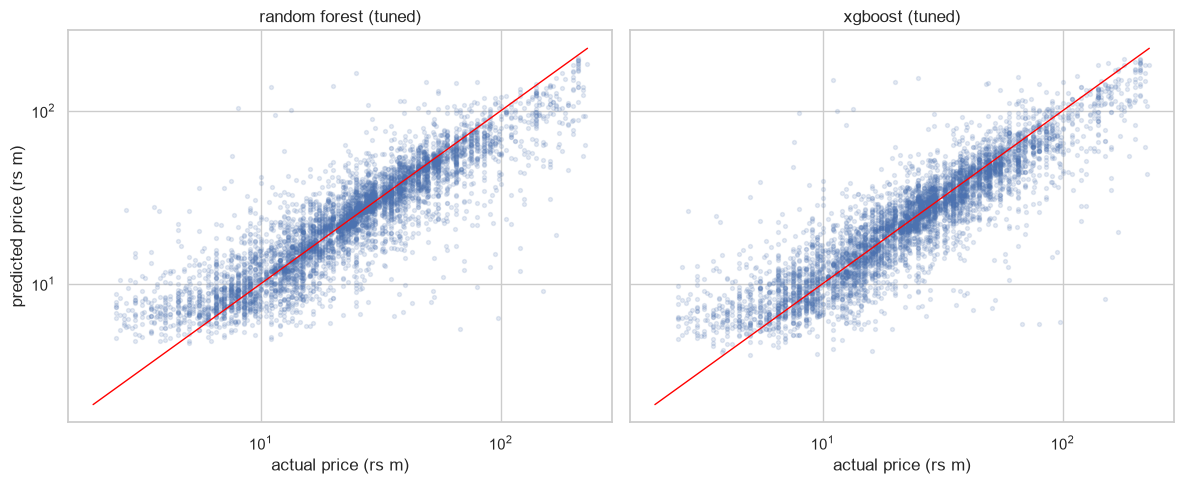

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for a, name in zip(ax, ['random forest (tuned)', 'xgboost (tuned)']):
    pred = models[name].predict(X_test)
    a.scatter(y_test / 1e6, pred / 1e6, alpha=.15, s=8)
    a.plot([2, 230], [2, 230], color='red', linewidth=1)
    a.set_xscale('log')
    a.set_yscale('log')
    a.set_title(name)
    a.set_xlabel('actual price (rs m)')
ax[0].set_ylabel('predicted price (rs m)')
plt.tight_layout()
plt.show()

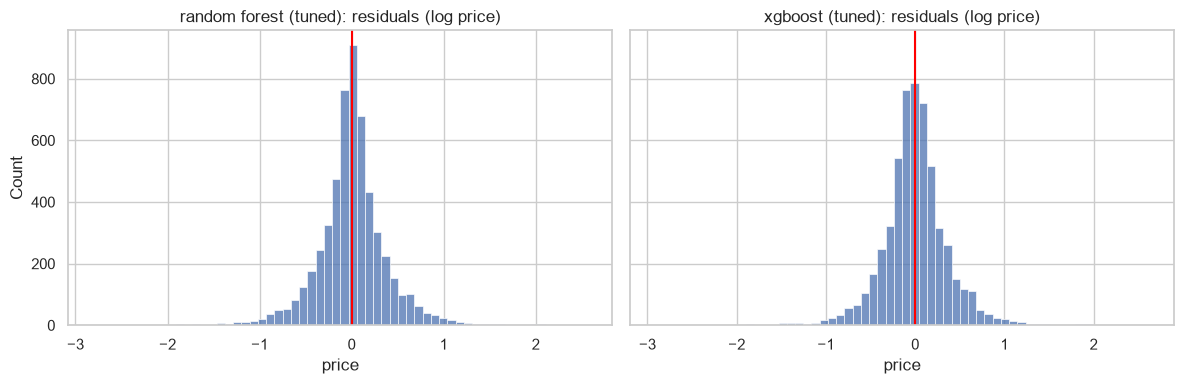

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, name in zip(ax, ['random forest (tuned)', 'xgboost (tuned)']):
    resid = np.log1p(models[name].predict(X_test)) - np.log1p(y_test)
    sns.histplot(resid, bins=60, ax=a)
    a.axvline(0, color='red')
    a.set_title(f'{name}: residuals (log price)')
plt.tight_layout()
plt.show()

### feature importance

permutation importance on a 3,000 row sample of the test set. columns are shuffled by original feature, so all the one hot columns of location move together.

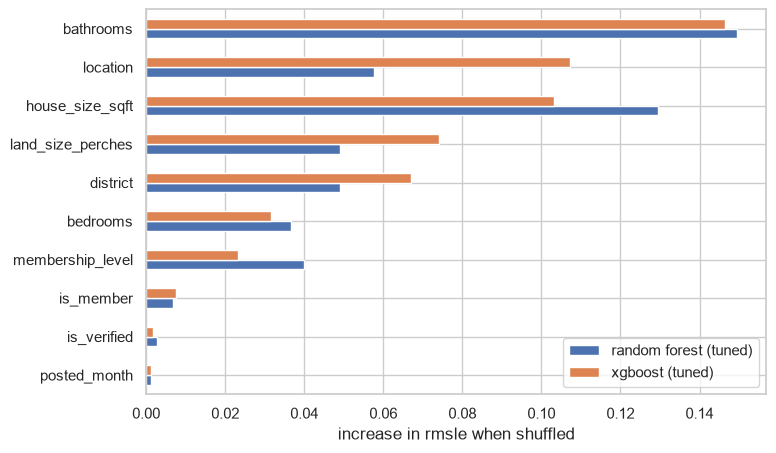

In [16]:
sub = X_test.sample(3000, random_state=SEED)
y_sub = y_test.loc[sub.index]

imp = {}
for name in ['random forest (tuned)', 'xgboost (tuned)']:
    r = permutation_importance(models[name], sub, y_sub, scoring=score, n_repeats=5, random_state=SEED, n_jobs=1)
    imp[name] = pd.Series(r.importances_mean, index=features)

imp = pd.DataFrame(imp).sort_values('xgboost (tuned)')
imp.plot.barh(figsize=(8, 5))
plt.xlabel('increase in rmsle when shuffled')
plt.show()

In [17]:
# error by district group, to see where the models struggle
pred = xgb_best.predict(X_test)
err = pd.DataFrame({'district': X_test['district'], 'abs_pct_err': np.abs(pred - y_test) / y_test * 100})
err['district'] = err['district'].where(err['district'].map(err['district'].value_counts()) > 100, 'other districts')
err.groupby('district')['abs_pct_err'].agg(['count', 'median']).round(1).sort_values('median')

,count,median
district,,
Colombo,3647,15.6
Kalutara,261,20.1
Gampaha,961,20.3
Kandy,177,31.5
other districts,499,31.7


### where the xgboost estimate is too high or too low

the houses are split into ten price bands of equal size and the median error is taken in each. a positive number means the estimate is too high.

the cheapest tenth (median rs 5.8 million) is overestimated by 42%, and the most expensive tenth (median rs 90 million) is underestimated by 19%. bands 3 to 8 are within about 5%. the model pulls everything towards the middle, so a cheap house gets a price that is too high and a luxury house one that is too low. keep that in mind when reading the app for either end.

the app shows a range of one test rmsle either side and says about 2 in 3 ads fall inside. on the test set 77.0% do, so the range is a bit wider than it needs to be.

In [18]:
# signed error by price band, positive means the estimate is above the real price
pred = xgb_best.predict(X_test)
pct = (pred - y_test) / y_test * 100
bands = pd.DataFrame({'band': pd.qcut(y_test, 10, labels=False) + 1, 'price': y_test / 1e6, 'signed': pct, 'abs': pct.abs()})
bands.groupby('band').agg(median_price_rs_m=('price', 'median'), median_signed_pct=('signed', 'median'),
                          median_abs_pct=('abs', 'median')).round(1)

,median_price_rs_m,median_signed_pct,median_abs_pct
band,,,
1,5.8,41.7,41.7
2,9.0,7.2,19.9
3,13.5,-2.0,19.7
4,17.5,3.1,19.0
5,22.5,-0.4,13.5
6,26.5,1.9,12.9
7,32.5,-4.6,13.1
8,40.0,-4.0,15.5
9,55.0,-9.3,15.3


In [19]:
# the app says about 2 in 3 ads fall inside the range, this checks it on the test set
spread = np.exp(results.loc['xgboost (tuned)', 'rmsle'])
inside = ((y_test >= pred / spread) & (y_test <= pred * spread)).mean()
print(f'{inside:.1%} of test houses are inside the range')

77.0% of test houses are inside the range


In [20]:
imp.round(4)

,random forest (tuned),xgboost (tuned)
posted_month,0.0013,0.0012
is_verified,0.0027,0.0016
is_member,0.0068,0.0076
membership_level,0.0399,0.0233
bedrooms,0.0366,0.0316
district,0.0491,0.0671
land_size_perches,0.0489,0.0740
house_size_sqft,0.1295,0.1031
location,0.0577,0.1071
bathrooms,0.1494,0.1464


### shap and partial dependence

shap on 2,000 test rows of the tuned xgboost, with the one hot columns of a feature added back together, and partial dependence of the main numbers.

mean absolute shap on log price: bathrooms 0.299, location 0.247, house size 0.167, district 0.144, land size 0.086, membership level 0.079 and bedrooms 0.071. posting month (0.012) and verified (0.011) are close to nothing. this agrees with the permutation importance above.

what the model learned matches what i expect. in the summary plot more bathrooms, a bigger house and a bigger plot all push the price up, and being in colombo pushes it up while piliyandala pulls it down, and dehiwala and nugegoda push it up. the average shap value of house size goes from -0.33 under 1,000 sqft to +0.06 at 2,000 to 3,000 and +0.40 above 5,000, so the price keeps rising with size. in the partial dependence the average price goes from about rs 20 million with 1 bathroom to about rs 45 million with 10 and rises fastest up to 4 bathrooms.

bedrooms is the one that looks odd. the price rises up to 4 bedrooms and then stays flat or drops a little. i think this is because bathrooms and house size already carry most of it, so for the same size more bedrooms just means smaller rooms. the plot of land size also has a step at about 25 perches, where there are few ads, so i do not read much into it.

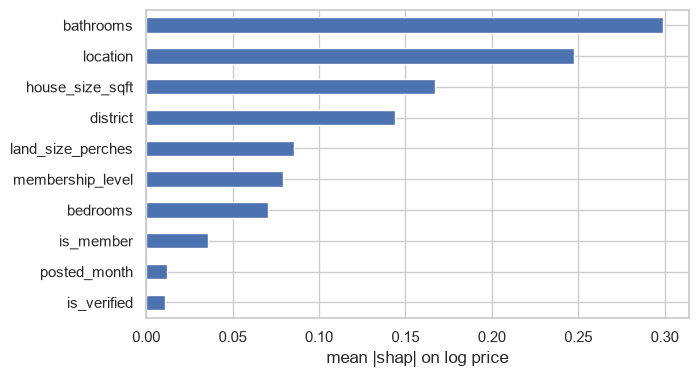

In [21]:
import shap

prep_fit = xgb_best.named_steps['prep']
booster = xgb_best.named_steps['model'].regressor_

shap_rows = X_test.sample(2000, random_state=SEED)
Z = prep_fit.transform(shap_rows)
names = list(prep_fit.get_feature_names_out())
shap_values = shap.TreeExplainer(booster).shap_values(Z)

# one hot columns of a feature are added back together
def original(name):
    kind, rest = name.split('__', 1)
    if kind == 'cat':
        return next(c for c in cat_cols if rest.startswith(c + '_'))
    return rest

groups = pd.Series([original(n) for n in names])
shap_importance = pd.DataFrame(np.abs(shap_values)).T.groupby(groups.values).sum().T.mean().sort_values()
shap_importance.plot.barh(figsize=(7, 4))
plt.xlabel('mean |shap| on log price')
plt.show()

In [22]:
shap_importance.round(3).sort_values(ascending=False)

bathrooms            0.299
location             0.247
house_size_sqft      0.167
district             0.144
land_size_perches    0.086
membership_level     0.079
bedrooms             0.071
is_member            0.036
posted_month         0.012
is_verified          0.011
dtype: float32

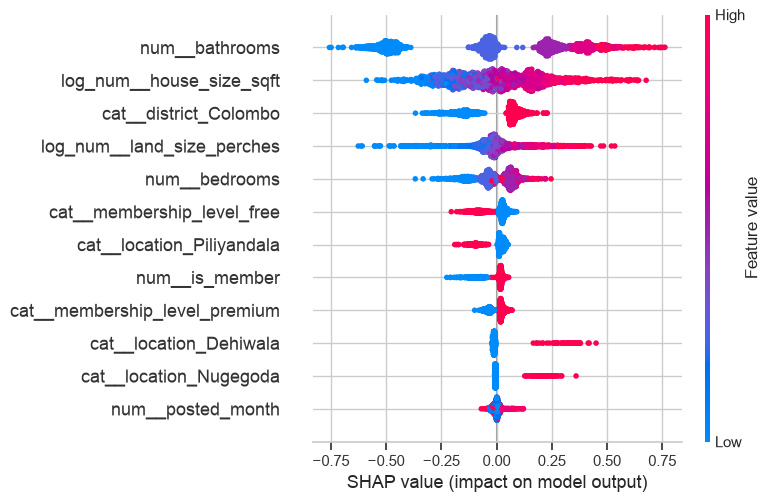

In [23]:
shap.summary_plot(shap_values, Z, feature_names=names, max_display=12, show=False)
plt.gcf().set_size_inches(8, 5)
plt.show()

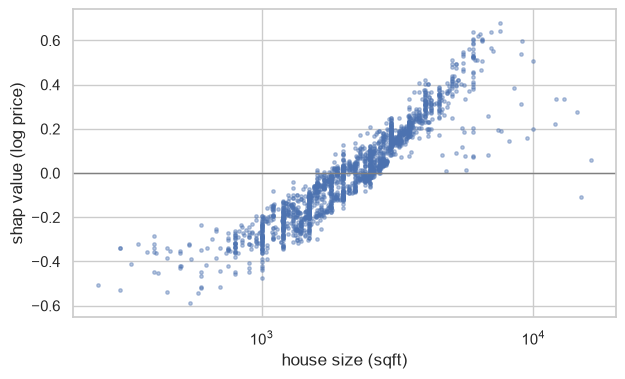

In [24]:
# shap value of house size against the real size, to see the shape the model learned
col = names.index('log_num__house_size_sqft')
plt.figure(figsize=(7, 4))
plt.scatter(shap_rows['house_size_sqft'], shap_values[:, col], s=6, alpha=.4)
plt.xscale('log')
plt.axhline(0, color='grey', linewidth=1)
plt.xlabel('house size (sqft)')
plt.ylabel('shap value (log price)')
plt.show()

In [25]:
# average shap value of house size in size bands
size_effect = pd.Series(shap_values[:, col]).groupby(pd.cut(shap_rows['house_size_sqft'].values, [0, 1000, 2000, 3000, 5000, 100000]))
size_effect.agg(['count', 'mean']).round(3)

,count,mean
"(0, 1000]",174,-0.328
"(1000, 2000]",777,-0.134
"(2000, 3000]",574,0.063
"(3000, 5000]",393,0.233
"(5000, 100000]",82,0.404


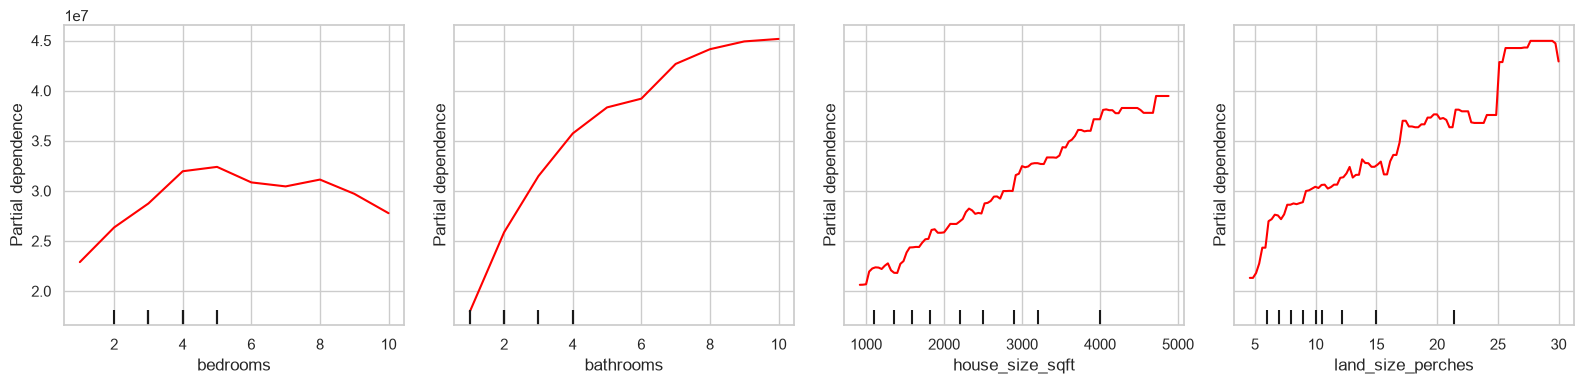

In [26]:
# partial dependence on the price scale, 5th to 95th percentile of each feature
fig, ax = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
PartialDependenceDisplay.from_estimator(xgb_best, shap_rows, ['bedrooms', 'bathrooms', 'house_size_sqft', 'land_size_perches'],
                                        kind='average', ax=ax, line_kw={'color': 'red'})
plt.tight_layout()
plt.show()

### explainable boosting machine

term importance is the mean absolute contribution to log price. location (0.223) and bathrooms (0.209) are the biggest, then house size (0.140), land size (0.105), bedrooms (0.089) and membership level (0.083). the biggest pair is house size with membership level (0.029). this is close to the xgboost shap order, but location is first here and bathrooms second.

the curves match what i expect, and they are exact. more bathrooms raise the price from about -0.37 at one bathroom to about +0.67 at seven or more, and the steps are largest up to four. bedrooms rise from -0.25 at one to +0.12 at five and then go flat or fall, the same odd shape as in the partial dependence of xgboost. house size and land size rise steadily on the log scale, from -0.35 under 500 sqft to +0.30 at 4,000 sqft, and from about -0.7 at one perch to +0.4 above 50 perches. above 8,000 sqft the curve drops, but there are very few ads there so i do not trust that end.

the district curve is small (-0.53 for anuradhapura, +0.30 for ampara, colombo +0.02) because the city term already carries most of the place effect.

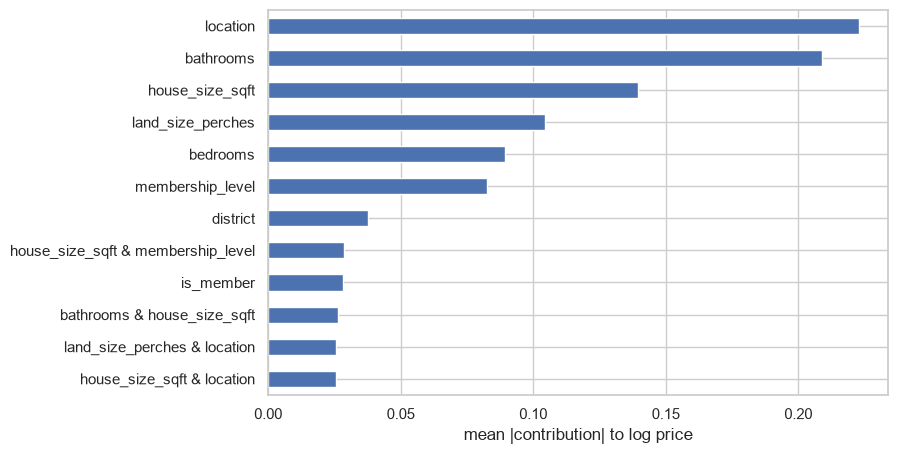

In [27]:
ebm = ebm_best.named_steps['model'].regressor_
ebm_global = ebm.explain_global()

# term importance is the mean absolute contribution to log price, interactions are named with an &
term_imp = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values()
term_imp.tail(12).plot.barh(figsize=(8, 5))
plt.xlabel('mean |contribution| to log price')
plt.show()

In [28]:
term_imp.sort_values(ascending=False).round(3).head(12)

location                              0.223
bathrooms                             0.209
house_size_sqft                       0.140
land_size_perches                     0.105
bedrooms                              0.089
membership_level                      0.083
district                              0.037
house_size_sqft & membership_level    0.029
is_member                             0.028
bathrooms & house_size_sqft           0.026
land_size_perches & location          0.026
house_size_sqft & location            0.026
dtype: float64

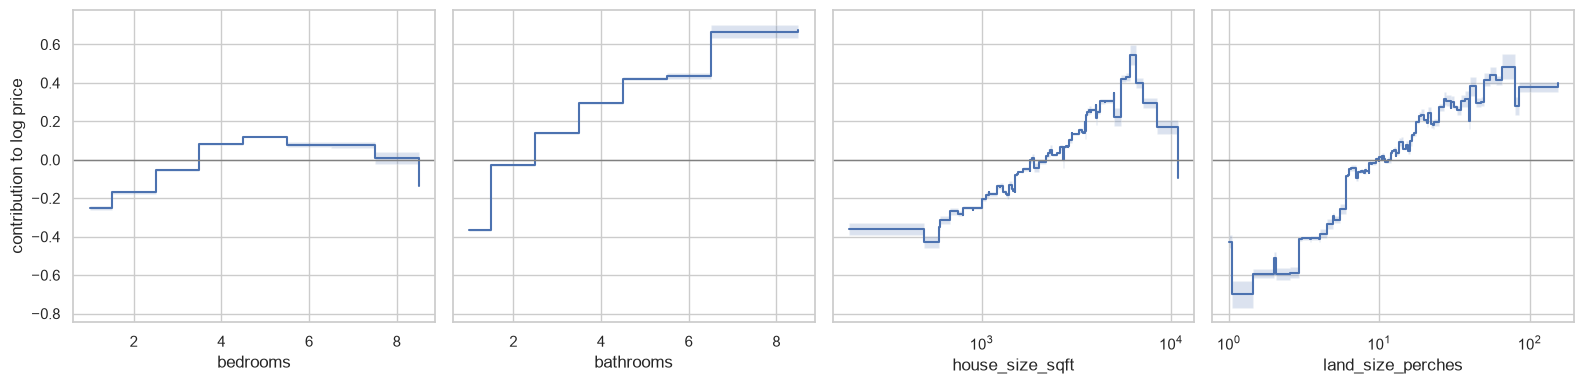

In [29]:
# the learned curve of each number: contribution to log price at each value
fig, ax = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for a, name in zip(ax, ['bedrooms', 'bathrooms', 'house_size_sqft', 'land_size_perches']):
    d = ebm_global.data(ebm.term_names_.index(name))
    edges, scores = np.array(d['names'], dtype=float), np.array(d['scores'], dtype=float)
    a.step(edges[:-1], scores, where='post')
    a.fill_between(edges[:-1], d['lower_bounds'], d['upper_bounds'], step='post', alpha=.2)
    a.axhline(0, color='grey', linewidth=1)
    a.set_xlabel(name)
    if name in ('house_size_sqft', 'land_size_perches'):
        a.set_xscale('log')
ax[0].set_ylabel('contribution to log price')
plt.tight_layout()
plt.show()

In [30]:
# location effect: the ten districts or places that push the price up or down the most
d = ebm_global.data(ebm.term_names_.index('district'))
district_effect = pd.Series(d['scores'], index=d['names']).sort_values()
district_effect.round(2)

Anuradhapura   -0.53
Polonnaruwa    -0.49
Trincomalee    -0.48
Hambantota     -0.46
Monaragala     -0.34
Kegalle        -0.28
Ratnapura      -0.13
Puttalam       -0.10
Kandy          -0.09
Nuwara Eliya   -0.09
Vavuniya       -0.06
Batticaloa     -0.06
Badulla        -0.05
Kalutara       -0.05
Mullativu      -0.02
Kilinochchi    -0.02
Mannar         -0.02
Galle          -0.02
Matara         -0.02
Gampaha         0.02
Colombo         0.02
Kurunegala      0.05
Matale          0.06
Jaffna          0.07
Ampara          0.30
dtype: float64

## what the results say

| model | test rmsle | cv rmsle |
|---|---|---|
| random forest (tuned) | 0.390 | 0.4006 |
| xgboost (tuned) | 0.377 | 0.3885 |
| voting | 0.378 | 0.3886 |
| stacking | 0.376 | 0.3870 |
| ebm (tuned) | 0.390 | 0.4012 |

**xgboost beats random forest.** 0.377 against 0.390 on the test set, and the cross validation says the same (0.389 against 0.401), so it is not luck. the gap is small, but all the models land in a narrow range. tuning helped xgboost more (0.389 to 0.377) than the forest (0.392 to 0.390).

**voting and stacking add almost nothing.** stacking is best at 0.376 but that is 0.001 better than xgboost alone. the two models make similar mistakes because they see the same features, so averaging them does not fix much. stacking is still the best on cv so it is the one i save.

**the ebm is about as good as the forest and a bit behind xgboost.** tuned it scores 0.390 on the test set and 0.4012 in cv, the same as the tuned forest (0.390 and 0.4006) and 0.013 behind xgboost (0.377). its median error is 19.9% against 17.7%. the default ebm scored 0.388, a little better than the tuned one on the test set, so my 6 draws did not find a better setting and i would not read anything into the 0.002. what i get for giving up 0.013 is a model whose every prediction can be explained exactly, and a pickle of 2.3 MB against 68 MB for the stack.

**the default random forest is better on some numbers.** its median error is 15.4% against 17.1% for the tuned one, and mae is 7.65 against 8.22 million. i tuned for rmsle and capped `min_samples_leaf` at 3 or more, and deep trees with leaves of 1 copy near identical ads from the same seller, which helps the typical house but hurts the big misses. so the tuned forest is a bit worse on the typical house and slightly better on the big misses.

**the error is large.** rmsle of 0.376 means about 68% of houses are within a factor of 1.46 of the real price (roughly minus 31% to plus 46%). median error is around 17%. asking prices are what sellers hope for, and nothing about the condition of the house, street or finishes is in the data.

**errors depend on the district.** median error is 15.6% in colombo (3,647 test ads) and 20% in gampaha and kalutara, but over 31% in kandy and the smaller districts. those have very few ads so the models have little to learn from.

**what the models use** (importance table above): bathrooms, house size, location and land size matter most. bathrooms ranks higher than bedrooms in both models, probably because bathrooms tell more about how big and modern the house is. location matters more to xgboost (0.107) than to the forest (0.058). seller membership level also matters a bit, premium sellers probably list pricier houses. posting month is close to zero (0.001), so the dates do not matter.

**random forest**
- strengths: hard to break, little tuning needed, deep trees fit repeated listings well
- limitations: big on disk (my first forest with unlimited depth and 400 trees was over 300 MB inside the stacked model, that is why i capped the leaf size and used 150 trees), cannot predict outside the price range it saw, and was the weakest model on cv

**xgboost**
- strengths: best single score, handles the noisy price better with regularisation, small saved model
- limitations: more parameters to tune, easier to overfit, and the learning curve showed the validation error flattens after about 670 rounds so more trees would not help

for the single listing i held out, see the inference section at the end.

## 8. saving the models

by cv score on the training set the stacking model is the best one, and it is the default in the web app. but the app lets the user pick, so the random forest, xgboost, ebm and stacking pipelines are all refitted on every row (train and test) and saved as pickles. each pickle holds the preprocessing too, so it takes raw column values. voting is not saved, it is just the average of the random forest and xgboost predictions on the log scale, so the app works it out from those two. the json files hold what the app needs (dropdown options, error sizes, price quantiles and the tables above).

In [31]:
best_name = cv_table.idxmin()
print('best by cv:', best_name)

to_save = {'random_forest': rf_best, 'xgboost': xgb_best, 'stacking': stacking, 'ebm': ebm_best}
for name, pipe in to_save.items():
    fitted = clone(pipe).fit(X, y)
    with open(f'../model/houses_{name}.pkl', 'wb') as f:
        pickle.dump(fitted, f)

best by cv: stacking (rf + xgb)


In [32]:
# info the web app needs: dropdown options, error size and price quantiles per district
test_rmsle = {
    'random forest': float(results.loc['random forest (tuned)', 'rmsle']),
    'xgboost': float(results.loc['xgboost (tuned)', 'rmsle']),
    'voting': float(results.loc['voting (rf + xgb)', 'rmsle']),
    'stacking': float(results.loc['stacking (rf + xgb)', 'rmsle']),
    'ebm': float(results.loc['ebm (tuned)', 'rmsle']),
}
loc_counts = df.groupby(['district', 'location']).size()
loc_counts = loc_counts[loc_counts >= 30]

district_sizes = df['district'].value_counts()
big_districts = district_sizes[district_sizes >= 100].index
qs = np.linspace(0, 1, 101)

meta = {
    'default_model': 'stacking',
    'test_rmsle': {k: round(v, 4) for k, v in test_rmsle.items()},
    'locations': {d: sorted(loc_counts[d].index.tolist()) for d in loc_counts.index.get_level_values(0).unique()},
    'membership_levels': sorted(df['membership_level'].dropna().unique().tolist()),
    'results': results.reset_index(names='model').to_dict('records'),
    'cv_rmsle': cv_table.to_dict(),
    'importance': imp.to_dict(),
    'best_params': {'random forest': rf_search.best_params_, 'xgboost': xgb_search.best_params_, 'ebm': ebm_search.best_params_},
    'price_quantiles': {d: df.loc[df['district'] == d, 'price'].quantile(qs).round(0).tolist() for d in big_districts},
}
with open('../model/houses_meta.json', 'w') as f:
    json.dump(meta, f)
print(meta['test_rmsle'], list(meta['price_quantiles']))

{'random forest': 0.39, 'xgboost': 0.377, 'voting': 0.378, 'stacking': 0.376, 'ebm': 0.39} ['Colombo', 'Gampaha', 'Kalutara', 'Kandy', 'Kurunegala', 'Galle', 'Kegalle', 'Matara', 'Ratnapura', 'Anuradhapura', 'Puttalam', 'Matale', 'Badulla', 'Hambantota']


## 9. predicting the held out listing

this listing never touched training, tuning or model choice. the pickles are loaded back from disk the same way the web app does it, and every model predicts it.

the real asking price was rs 35,000,000. stacking says rs 44.0 million (25.7% too high), xgboost rs 42.6 million (21.7%), voting rs 47.9 million (36.7%) and the random forest is furthest at rs 53.8 million (53.6%). the ebm is closest at rs 38.2 million (9.3%). all of them overshoot. the house is in piliyandala, which has the most ads of any location, with 6 bedrooms and 3,500 sqft, bigger than the typical listing there, so a miss like this is not surprising. one listing says little about which model is better, the test set scores above are the fair comparison.

In [33]:
loaded = {}
for name in ['random_forest', 'xgboost', 'stacking', 'ebm']:
    with open(f'../model/houses_{name}.pkl', 'rb') as f:
        loaded[name] = pickle.load(f)

with open('../model/houses_holdout_sample.json') as f:
    saved = json.load(f)

new_point = pd.DataFrame([saved['features']])
actual = saved['actual_price']

preds = {name: loaded[name].predict(new_point)[0] for name in loaded}
# voting is the mean of the two log predictions
preds['voting'] = np.expm1((np.log1p(preds['random_forest']) + np.log1p(preds['xgboost'])) / 2)

print(new_point.T.to_string(header=False))
print(f'actual: rs {actual:,.0f}\n')
for name, value in preds.items():
    print(f'{name:14s} rs {value:>12,.0f}   error {abs(value - actual) / actual * 100:5.1f}%')

bedrooms                   6.0
bathrooms                  4.0
house_size_sqft         3500.0
land_size_perches         20.0
posted_month               2.0
is_verified                  0
location           Piliyandala
district               Colombo
membership_level          free
is_member                  0.0
actual: rs 35,000,000

random_forest  rs   53,772,450   error  53.6%
xgboost        rs   42,584,844   error  21.7%
stacking       rs   43,991,210   error  25.7%
ebm            rs   38,248,516   error   9.3%
voting         rs   47,852,809   error  36.7%
